# Demostración: Detección de Anomalías en un Proceso Electoral Simulado

> **Descargo ético obligatorio:**
> *Todos los datos de este proyecto son simulados. Los nombres de país, departamentos, municipios y candidatos son ficticios. Los resultados no representan ni hacen afirmaciones sobre ningún proceso electoral real. Una alerta generada por los detectores indica una inconsistencia que merece revisión, no una prueba de fraude.*

## 1. Cargar el dataset simulado y las dependencias del proyecto

In [1]:
import sys
from pathlib import Path
# Asegurar que la raíz del proyecto esté en sys.path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()))

import pandas as pd
from IPython.display import Image, display
from src.config import DATA_RAW_CSV, DATA_PROCESSED_CSV, OUTPUTS_FIG_DIR, OUTPUTS_TAB_DIR, SEED
from src.generate_dataset import generar_dataset
from src.features import agregar_features
from src.rules import aplicar_reglas
from src.isolation_forest import aplicar_isolation_forest
from src.evaluate import ejecutar_evaluacion

# Cargar o regenerar dataset
df_raw = pd.read_csv(DATA_RAW_CSV) if DATA_RAW_CSV.exists() else generar_dataset(seed=SEED)
print(f"Total de mesas cargadas: {len(df_raw)}")
df_raw.head()

Total de mesas cargadas: 5000


,mesa_id,departamento,municipio,zona,puesto,votantes_habilitados,votos_cand_A,votos_cand_B,votos_cand_C,votos_cand_D,votos_blanco,votos_nulos,votos_no_marcados,total_votos_reportado,hora_reporte,es_anomalia,tipo_anomalia,nota_simulacion
0,M00001,Aurora,Aurora-Mun01,rural,Aurora-Mun01-P01,270,84,26,21,16,7,6,1,161,2026-03-08T17:43:00,0,ninguna,NaN
1,M00002,Aurora,Aurora-Mun01,rural,Aurora-Mun01-P01,237,40,17,36,7,3,3,2,108,2026-03-08T19:57:00,0,ninguna,NaN
2,M00003,Aurora,Aurora-Mun01,rural,Aurora-Mun01-P01,107,36,10,14,4,2,1,0,67,2026-03-08T19:17:00,0,ninguna,NaN
3,M00004,Aurora,Aurora-Mun01,rural,Aurora-Mun01-P01,276,60,50,41,9,5,7,1,173,2026-03-08T17:08:00,0,ninguna,NaN
4,M00005,Aurora,Aurora-Mun01,rural,Aurora-Mun01-P01,138,34,27,16,4,0,5,0,86,2026-03-08T21:01:00,0,ninguna,NaN


## 2. Aplicar Ingeniería de Características (Features) y Reglas Simples

In [2]:
df_feat = agregar_features(df_raw)
df_reglas = aplicar_reglas(df_feat)
print(f"Mesas alertadas por reglas simples: {df_reglas['alerta_reglas'].sum()}")
df_reglas['severidad_reglas'].value_counts()

Mesas alertadas por reglas simples: 193


severidad_reglas
sin alerta    4807
critica         81
alta            57
media           55
Name: count, dtype: int64

## 3. Aplicar Detección no supervisada con Isolation Forest

In [3]:
df_proc, modelo_if, scaler = aplicar_isolation_forest(df_reglas, seed=SEED)
print(f"Mesas alertadas por Isolation Forest (top 4% outliers): {df_proc['alerta_if'].sum()}")
df_proc[['mesa_id', 'participacion', 'pct_max_candidato', 'score_if', 'alerta_if', 'ranking_if']].head()

Mesas alertadas por Isolation Forest (top 4% outliers): 200


,mesa_id,participacion,pct_max_candidato,score_if,alerta_if,ranking_if
0,M00001,0.596296,0.571429,0.402528,False,3313
1,M00002,0.455696,0.400000,0.452419,False,996
2,M00003,0.626168,0.562500,0.443435,False,1261
3,M00004,0.626812,0.375000,0.441491,False,1326
4,M00005,0.623188,0.419753,0.423002,False,2095


## 4. Evaluación contra Ground Truth y Métricas de Clasificación

In [4]:
df_final, tablas = ejecutar_evaluacion(df_proc)
display(tablas['metricas'])
display(tablas['recall_tipo'])

EVALUACIÓN DE DETECTORES (GROUND TRUTH)
            detector  mesas_alertadas  VP  FP  precision  recall       f1
      Reglas simples              193 188   5   0.974093   0.940 0.956743
    Isolation Forest              200 117  83   0.585000   0.585 0.585000
  Unión (Cualquiera)              276 193  83   0.699275   0.965 0.810924
Intersección (Ambas)              117 112   5   0.957265   0.560 0.706625

Recall por tipo de anomalía:
            tipo_anomalia  recall_reglas  recall_if  recall_union
      sobre_participacion       1.000000   0.900000      1.000000
            relleno_urnas       0.733333   0.488889      0.844444
             voto_unanime       1.000000   1.000000      1.000000
inconsistencia_aritmetica       1.000000   0.371429      1.000000
         numeros_redondos       1.000000   0.360000      1.000000
          nulos_excesivos       1.000000   0.366667      1.000000

Falsos positivos en casos extremos legítimos (40 mesas):
            detector  falsos_positivos  

,detector,mesas_alertadas,VP,FP,FN,VN,precision,recall,f1
0,Reglas simples,193,188,5,12,4795,0.974093,0.940,0.956743
1,Isolation Forest,200,117,83,83,4717,0.585000,0.585,0.585000
2,Unión (Cualquiera),276,193,83,7,4717,0.699275,0.965,0.810924
3,Intersección (Ambas),117,112,5,88,4795,0.957265,0.560,0.706625


,tipo_anomalia,total_inyectadas,recall_reglas,recall_if,recall_union,recall_interseccion
0,sobre_participacion,30,1.000000,0.900000,1.000000,0.900000
1,relleno_urnas,45,0.733333,0.488889,0.844444,0.377778
2,voto_unanime,35,1.000000,1.000000,1.000000,1.000000
3,inconsistencia_aritmetica,35,1.000000,0.371429,1.000000,0.371429
4,numeros_redondos,25,1.000000,0.360000,1.000000,0.360000
5,nulos_excesivos,30,1.000000,0.366667,1.000000,0.366667


## 5. Visualizaciones Oficiales del Proceso

=== fig1_distribucion_participacion.png ===


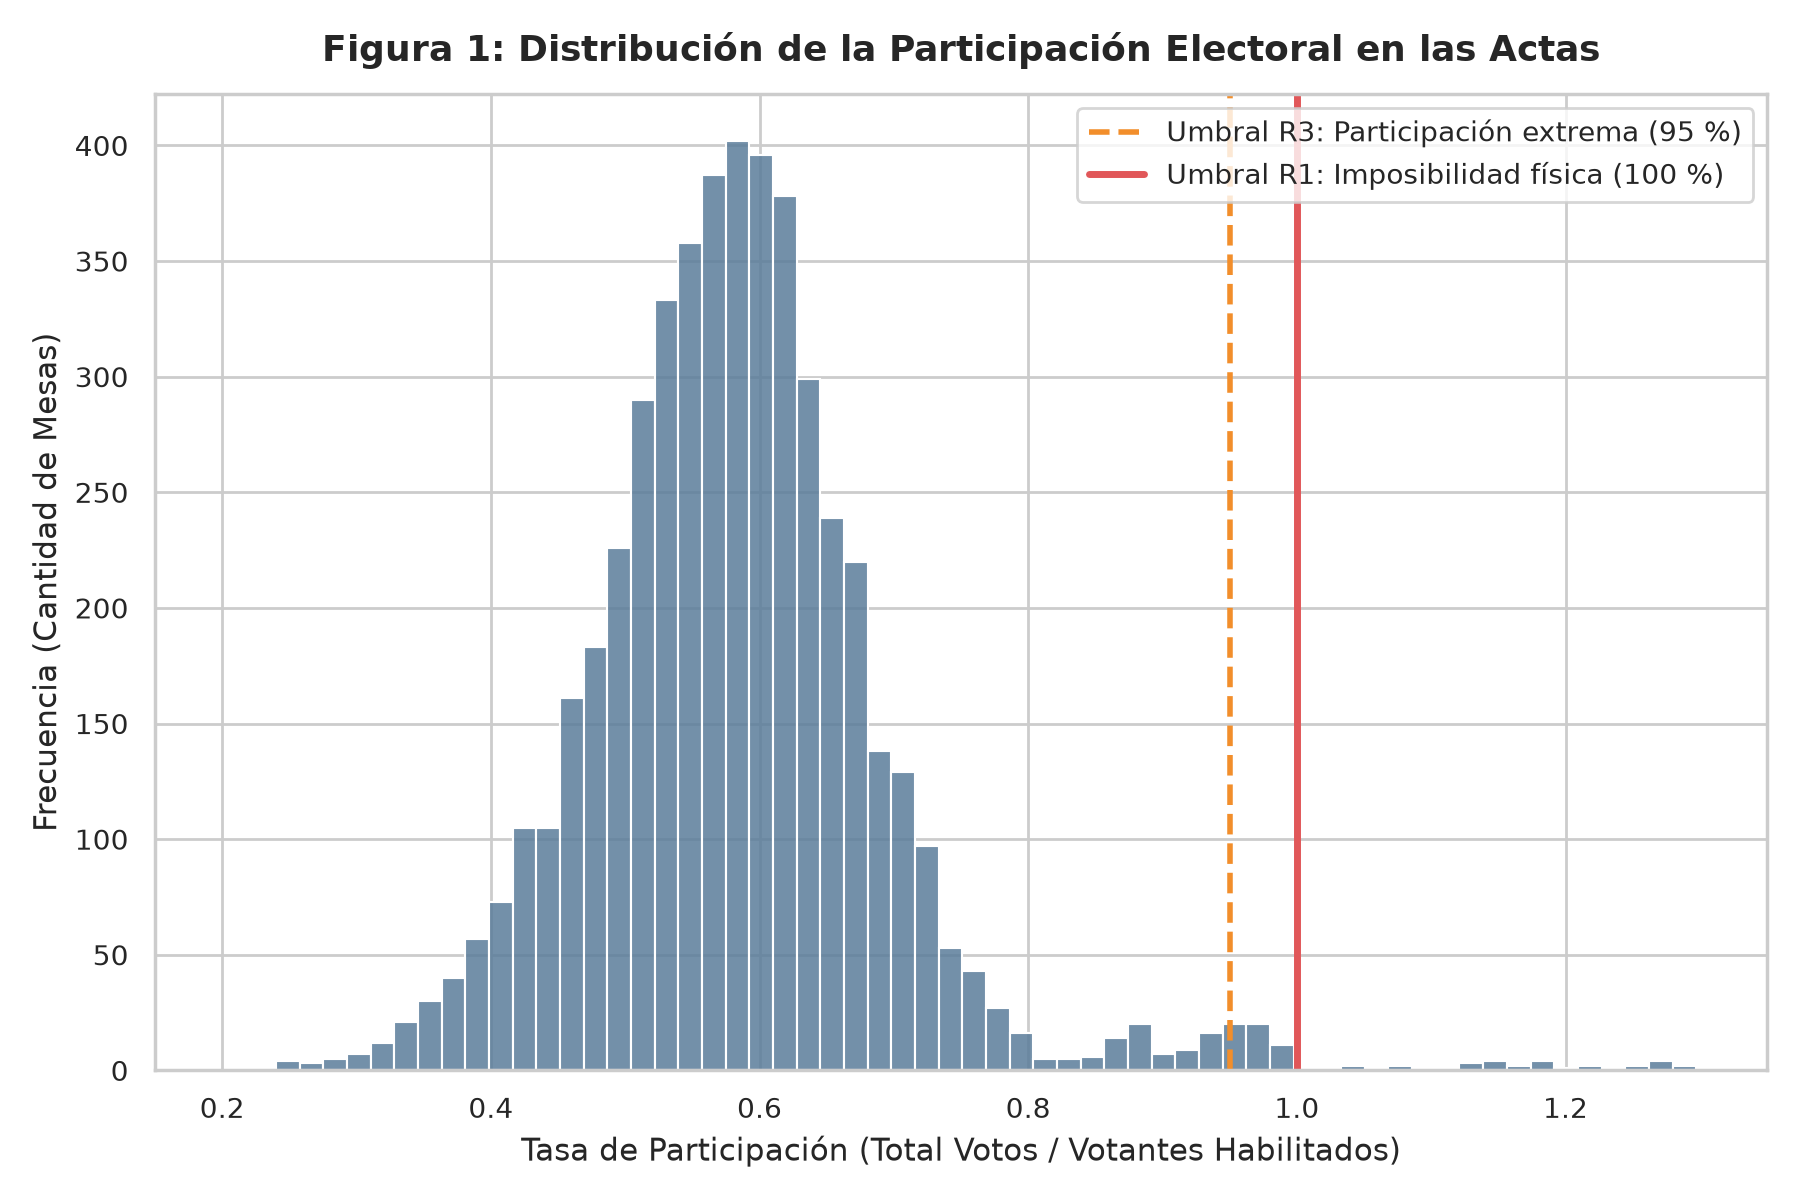

=== fig2_huella_electoral.png ===


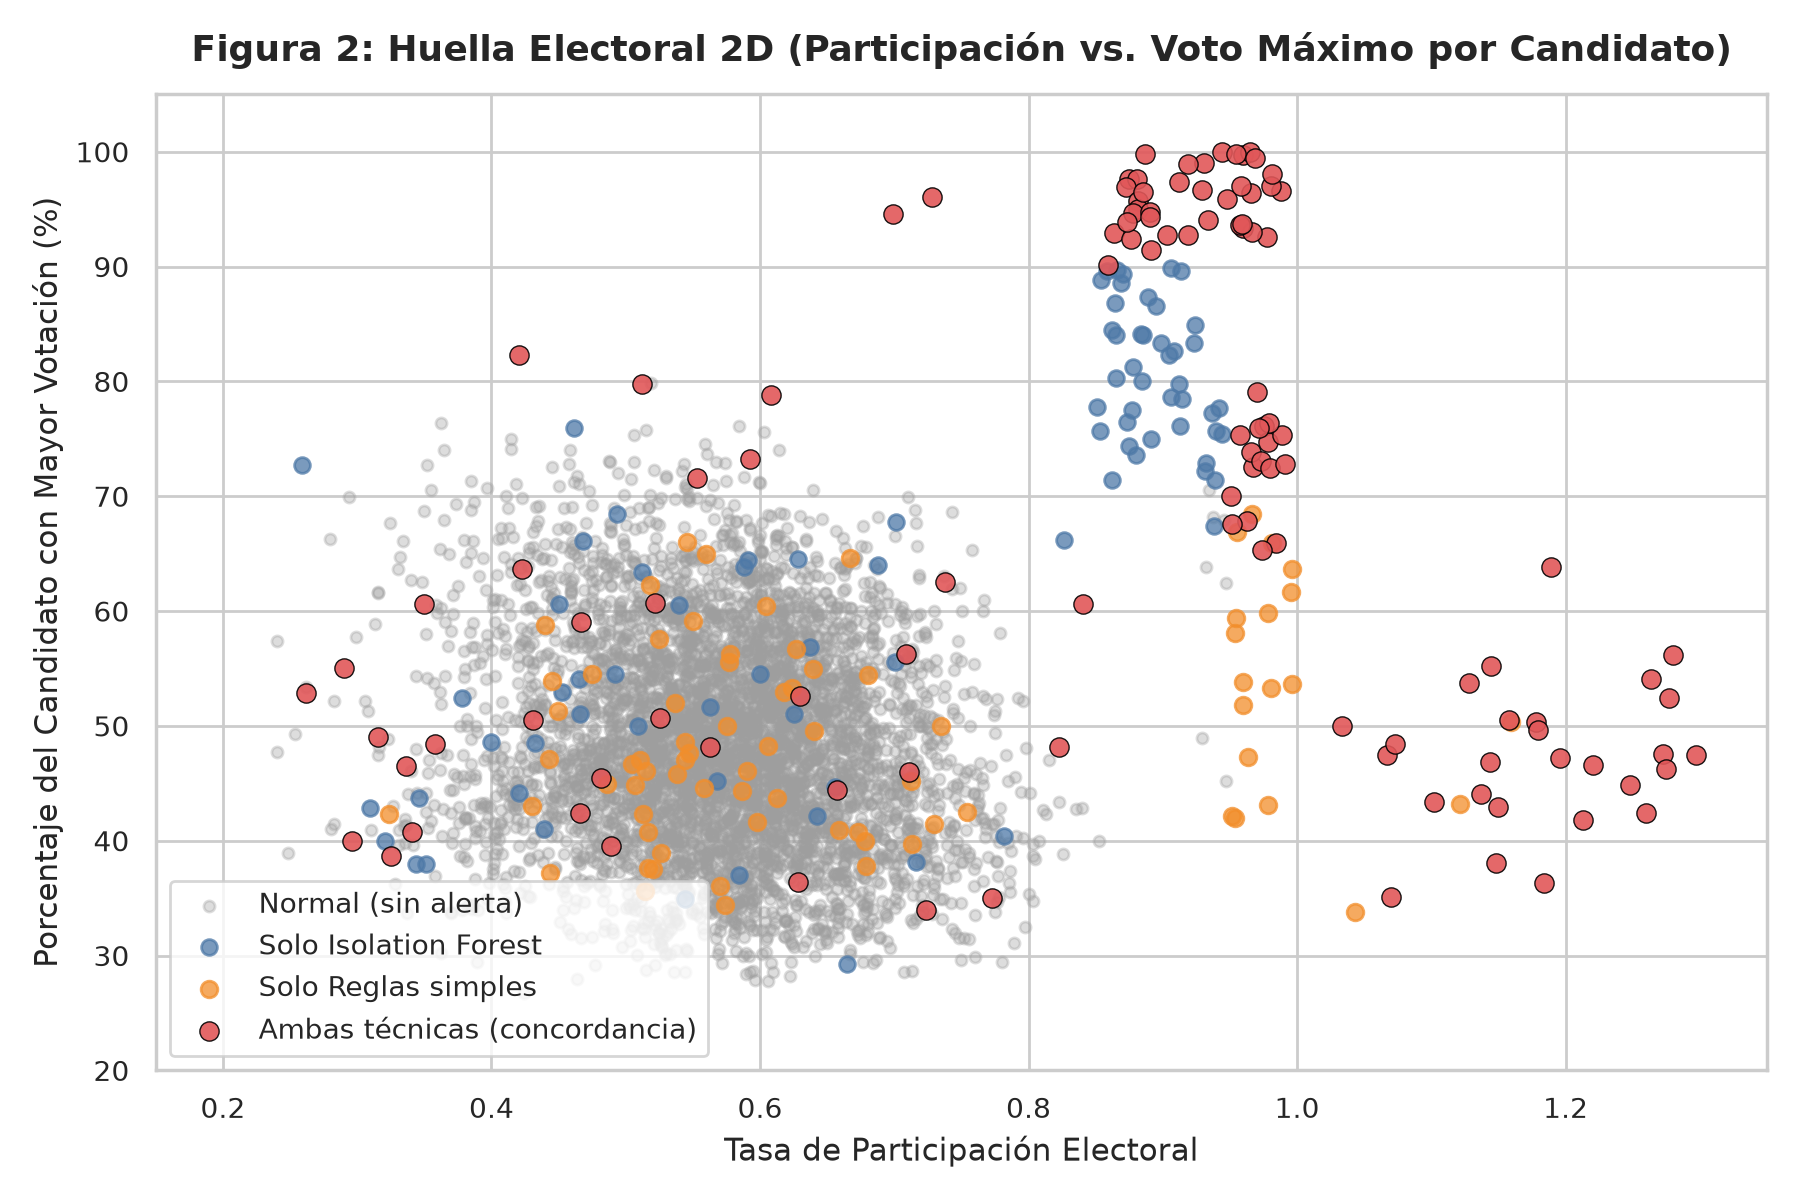

=== fig3_score_isolation_forest.png ===


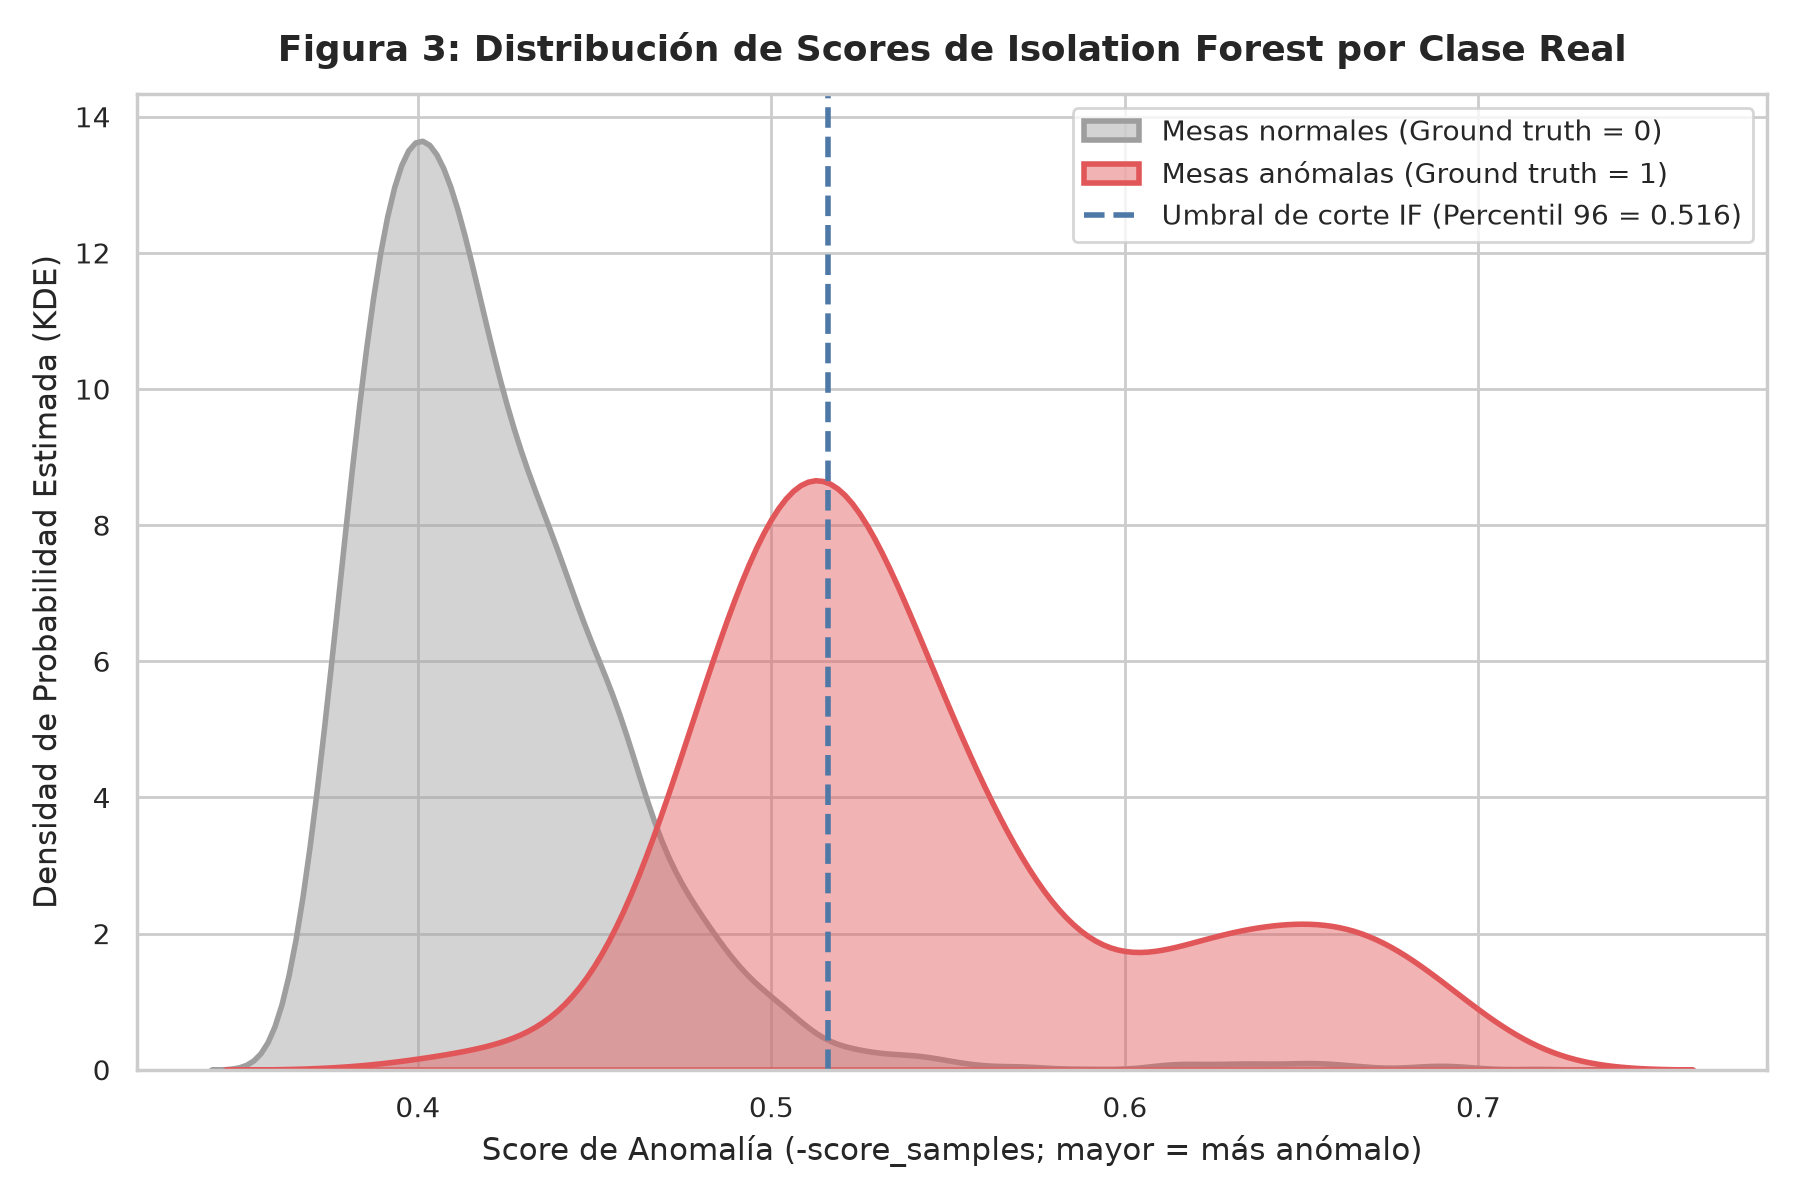

=== fig4_recall_por_tipo.png ===


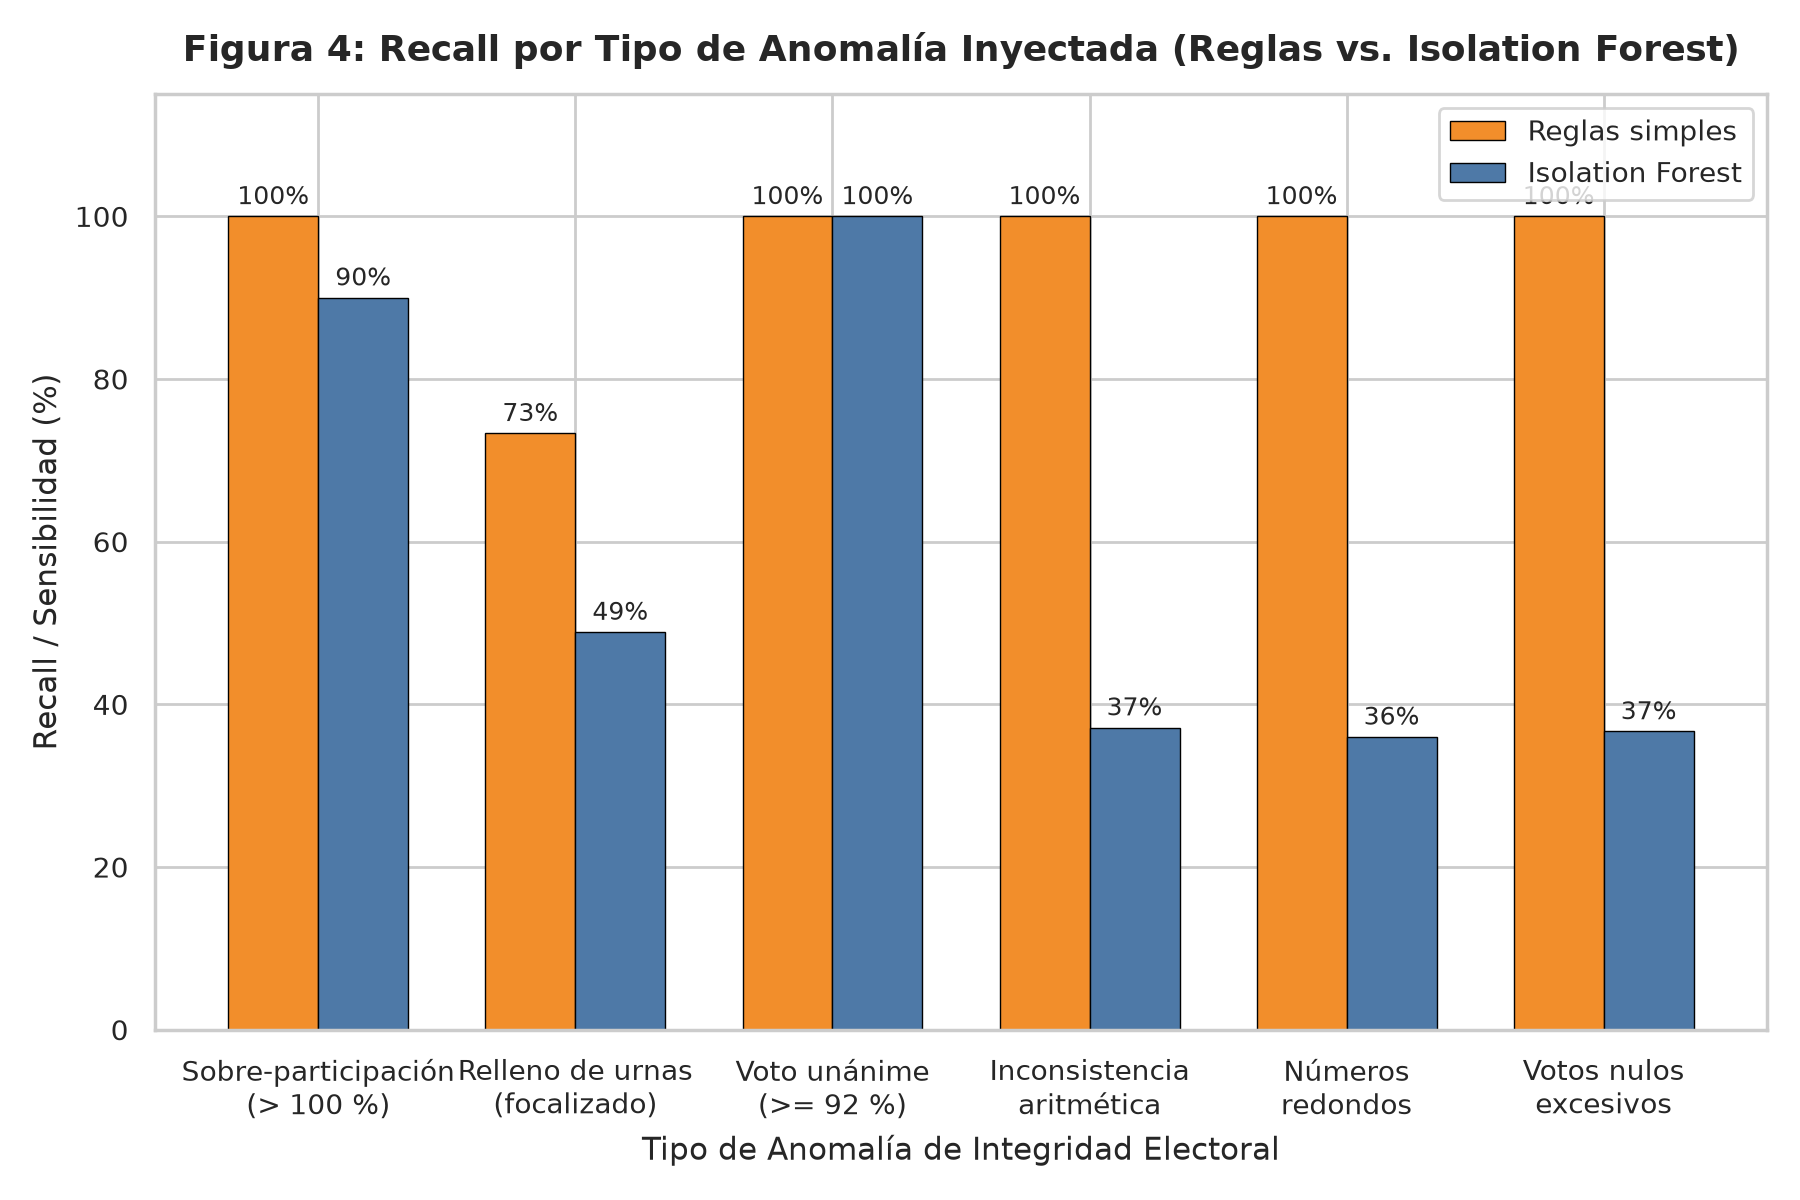

=== fig5_riesgo_por_municipio.png ===


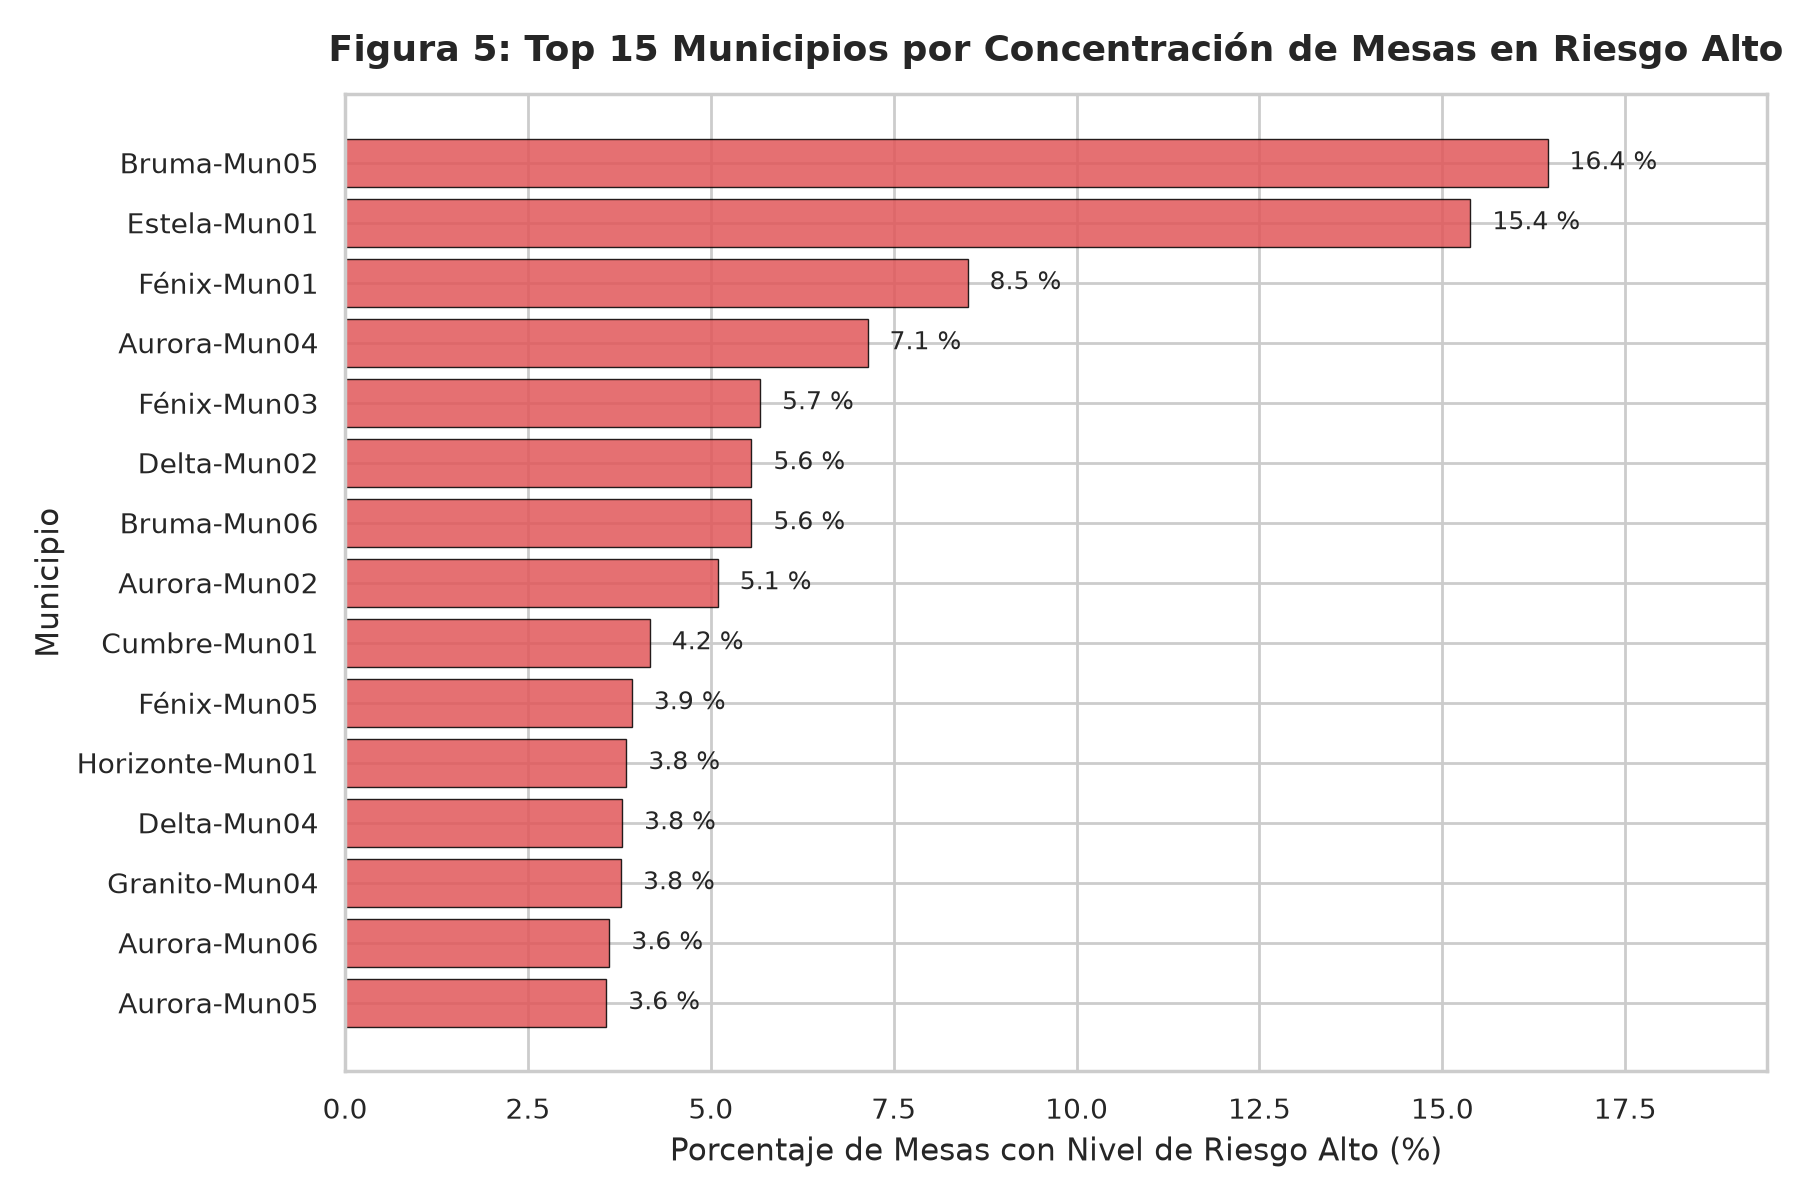

In [5]:
figuras = [
    "fig1_distribucion_participacion.png",
    "fig2_huella_electoral.png",
    "fig3_score_isolation_forest.png",
    "fig4_recall_por_tipo.png",
    "fig5_riesgo_por_municipio.png"
]
for f in figuras:
    print(f"=== {f} ===")
    display(Image(filename=str(OUTPUTS_FIG_DIR / f)))


## 6. Top 5 Mesas más Sospechosas y Explicación en Detalle

In [6]:
top_5 = tablas['top_15'].head(5)
display(top_5)

mesa_ejemplo = top_5.iloc[0]
print("\n--- EXPLICACIÓN DE LA MESA #1 PRIORIZADA PARA AUDITORÍA ---")
print(f"Mesa ID: {mesa_ejemplo['mesa_id']} en {mesa_ejemplo['municipio']} ({mesa_ejemplo['departamento']})")
print(f"Votantes habilitados: {mesa_ejemplo['votantes_habilitados']} | Total reportado: {mesa_ejemplo['total_votos_reportado']}")
print(f"Participación: {mesa_ejemplo['participacion'] * 100:.2f} % (Sobre-participación física imposible)")
print(f"Nivel de riesgo: {mesa_ejemplo['nivel_riesgo']} (Severidad reglas: {mesa_ejemplo['severidad_reglas']}, Score IF: {mesa_ejemplo['score_if']:.4f})")
print(f"Tipo real inyectado (Ground Truth): {mesa_ejemplo['tipo_anomalia']}")
print("Acción recomendada: Apertura inmediata del sobre electoral para recuento manual papeleta por papeleta.")

,ranking,mesa_id,departamento,municipio,zona,total_votos_reportado,votantes_habilitados,participacion,diferencia_aritmetica,pct_max_candidato,pct_nulos,frac_multiplos_10,nivel_riesgo,severidad_reglas,puntaje_reglas,score_if,alerta_reglas,alerta_if,es_anomalia,tipo_anomalia
1853,1,M01854,Delta,Delta-Mun03,rural,147,137,1.072993,0,0.484127,0.047619,0.00,alto,critica,5,0.594802,True,True,1,sobre_participacion
1078,2,M01079,Bruma,Bruma-Mun06,rural,128,100,1.280000,0,0.561983,0.039062,0.00,alto,critica,5,0.582580,True,True,1,sobre_participacion
3715,3,M03716,Granito,Granito-Mun04,rural,115,91,1.263736,0,0.540541,0.017391,0.25,alto,critica,5,0.578271,True,True,1,sobre_participacion
1998,4,M01999,Delta,Delta-Mun04,urbana,576,472,1.220339,0,0.465549,0.024306,0.50,alto,critica,5,0.572638,True,True,1,sobre_participacion
2970,5,M02971,Fénix,Fénix-Mun03,urbana,751,596,1.260067,0,0.424113,0.037284,0.25,alto,critica,5,0.559765,True,True,1,sobre_participacion



--- EXPLICACIÓN DE LA MESA #1 PRIORIZADA PARA AUDITORÍA ---
Mesa ID: M01854 en Delta-Mun03 (Delta)
Votantes habilitados: 137 | Total reportado: 147
Participación: 107.30 % (Sobre-participación física imposible)
Nivel de riesgo: alto (Severidad reglas: critica, Score IF: 0.5948)
Tipo real inyectado (Ground Truth): sobre_participacion
Acción recomendada: Apertura inmediata del sobre electoral para recuento manual papeleta por papeleta.
